<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h1>Homework, Task 3 and 4: Feature selection, model and assessment</h1>

<p>We start from the pre-processing of Task 2 (imported from <code>preprocessing.py</code>). In Task 3 we first check the ID-like
variables and then select features with one filter, one wrapper and one embedded method from Week 4. In Task 4 we compare the
models from Weeks 5 and 6, tune the penalty and the threshold for later purchases (like test.csv) and write the Kaggle file.</p>

<h2>Contents</h2>
<ol>
  <li><a href="#setup">Setup and validation design</a></li>
  <li><a href="#idlike">ID-like variables</a></li>
  <li><a href="#selection">Feature selection</a></li>
  <li><a href="#model">Model and assessment</a></li>
  <li><a href="#finalset">Final model and feature set</a></li>
  <li><a href="#submission">Predictions for test.csv</a></li>
</ol>

</div>

<a id="setup"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>1. Setup and validation design</h2>

</div>

In [15]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr

from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

# preprocessing.py sits next to this notebook or in the Final folder
for folder in [Path.cwd(), Path.cwd() / "Final"]:
    if (folder / "preprocessing.py").is_file():
        sys.path.insert(0, str(folder))
from preprocessing import preprocessor

DATA_DIR = next(p for p in [Path("data"), Path("../data"), Path(".")] if (p / "train.csv").is_file())

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")   # convergence and one-hot warnings, known and expected
RANDOMSTATE = 42
TARGET = "repeat_purchase_90d"
print("scikit-learn", sklearn_version)

scikit-learn 1.9.0


In [16]:
trainraw = pd.read_csv(DATA_DIR / "train.csv")

# same row exclusion as Task 2: drop the 65 rows without any feature
featurecols = [c for c in trainraw.columns if c not in ["ID", "customer_id", TARGET]]
train = trainraw[~trainraw[featurecols].isna().all(axis=1)].reset_index(drop=True)
X, y, groups = train.drop(columns=TARGET), train[TARGET], train["customer_id"]

# the two clientes columns from Task 2 (4), joined by customer_id: a lookup, nothing is fitted
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
clientes = clientes.assign(island_known=clientes["island"].notna().astype(int))[["customer_id", "country_or_region", "island_known"]]
addclientes = lambda df: df.merge(clientes, on="customer_id", how="left").set_axis(df.index)
X = addclientes(X)

# candidate features from Task 2 (after cleaning and the new features)
NUMERIC = ["Total Liquido", "Total Imp_", "Total Portes", "Total Desc_ Global", "Total Desc_ Linha", "Custo",
           "N_ Detalhes", "invoice_count_current_purchase",
           "days_since_previous_purchase", "customer_tenure_days", "prior_purchase_count", "prior_total_spend",
           "prior_mean_purchase_value", "prior_std_purchase_value", "prior_min_purchase_value",
           "prior_max_purchase_value", "prior_mean_gap_days", "prior_std_gap_days",
           "purchase_count_30d", "spend_30d", "purchase_count_90d", "spend_90d",
           "purchase_count_180d", "spend_180d", "purchase_count_365d", "spend_365d",
           "purchases_per_year", "discount_rate"]
FLAGS = ["is_first_purchase", "has_gap_history", "typical_gap_le_90", "zero_cost", "has_shipping"]
CATEGORICAL = ["payment_type", "salesperson", "commercial_zone", "transport_method", "month"]

# the same 5 customer folds as in Task 2
splits = list(GroupKFold(n_splits=5).split(X, y, groups))
print(f"{len(X)} rows, {groups.nunique()} customers, repeat rate {y.mean():.3f}")

Task was destroyed but it is pending!
task: <Task pending name='Task-115' coro=<_async_in_context.<locals>.run_in_context() done, defined at /opt/anaconda3/envs/machine_learning/lib/python3.13/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-116' coro=<Kernel.shell_main() running at /opt/anaconda3/envs/machine_learning/lib/python3.13/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /opt/anaconda3/envs/machine_learning/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py:564]>
Task was destroyed but it is pending!
task: <Task pending name='Task-116' coro=<Kernel.shell_main() running at /opt/anaconda3/envs/machine_learning/lib/python3.13/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


6469 rows, 607 customers, repeat rate 0.560


In [17]:
# prepare every fold once, fitted on the training part only (Week 5, cached schema)
def foldmatrices(categorical, folds=splits, frame=X, flags=FLAGS):
    out = []
    for trainidx, validx in folds:
        prep = preprocessor(NUMERIC, flags, categorical)
        Atrain = prep.fit_transform(frame.iloc[trainidx])
        Aval = prep.transform(frame.iloc[validx])
        out.append((Atrain, Aval, prep.named_steps["columns"].get_feature_names_out()))
    return out


# held-out probabilities per fold (logistic regression by default), only on the columns in masks (default: all)
def heldoutprob(matrices, masks=None, model=None, folds=splits, target=y):
    probs = []
    for i, ((Atrain, Aval, names), (trainidx, _)) in enumerate(zip(matrices, folds)):
        keep = np.ones(len(names), bool) if masks is None else masks[i]
        fitted = clone(model or LogisticRegression(max_iter=2000)).fit(Atrain[:, keep], target.iloc[trainidx])
        probs.append(fitted.predict_proba(Aval[:, keep])[:, 1])
    return probs


# F1 (at a threshold) or AUC per fold
def foldscores(probs, folds=splits, target=y, threshold=0.5, metric="F1"):
    return np.array([f1_score(target.iloc[va], p >= threshold) if metric == "F1" else roc_auc_score(target.iloc[va], p)
                     for (_, va), p in zip(folds, probs)])


def heldoutf1(matrices, masks=None, model=None, threshold=0.5, folds=splits, target=y):
    return foldscores(heldoutprob(matrices, masks, model, folds, target), folds, target, threshold)


# Week 4 rule: a difference only counts if it is bigger than 2 standard errors of the paired fold differences
def paired(scores, reference):
    diff = np.asarray(scores) - np.asarray(reference)
    sem = diff.std(ddof=1) / np.sqrt(len(diff))
    verdict = ("same columns" if not diff.any() else "inside the noise" if abs(diff.mean()) <= 2 * sem
               else "better" if diff.mean() > 0 else "worse")
    return {"dF1": round(float(diff.mean()), 4), "SEM": round(float(sem), 4), "better in": f"{(diff > 0).sum()}/{len(diff)}",
            "verdict": verdict}

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Validation design</b></p>
<ul>
  <li>One customer has about 10 rows, so we keep the <b>GroupKFold by customer</b> from Task 2 --> no customer is in training and validation at the same time</li>
  <li>Every step that learns something (fills, scaling, one-hot, the selectors) is fitted <b>inside the training folds</b></li>
  <li>Until Task 4 we use <b>F1 of class 1 at a threshold of 0.5</b>, the threshold itself is chosen later (4.4)</li>
  <li>For the final tuning (4.3) we add a <b>time split</b>, because test.csv holds later purchases</li>
  <li>A difference only counts if it is larger than <b>2 standard errors</b> of the five paired fold differences (Week 4), otherwise it is noise</li>
</ul>

</div>

<a id="idlike"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>2. ID-like variables</h2><p>Columns that mostly tell <i>which</i> row or customer it is can not generalise. We check every candidate.</p>

</div>

In [18]:
# for each column: number of levels, rows per level and levels that belong to only one customer
idcheck = {}
for col in ["ID", "customer_id", "transport_method", "salesperson", "payment_type", "document_series"]:
    levels = X[col].dropna()
    customers_per_level = X.groupby(col)["customer_id"].nunique()
    idcheck[col] = {"Levels": levels.nunique(), "Rows per level": round(len(levels) / levels.nunique(), 1),
                    "Levels with only one customer": int((customers_per_level == 1).sum())}
display(pd.DataFrame(idcheck).T.rename_axis("Variable"))

# transport_method: how much of a customer's rows use one single level?
top_share = (X.groupby("customer_id")["transport_method"]
              .agg(lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan))
print(f"transport_method: median share of a customer's rows with their most used level = {top_share.median():.2f}")

,Levels,Rows per level,Levels with only one customer
Variable,,,
ID,6469.0,1.0,6469.0
customer_id,607.0,10.7,607.0
transport_method,80.0,78.4,40.0
salesperson,9.0,697.2,0.0
payment_type,9.0,697.1,0.0
document_series,3.0,2156.3,0.0


transport_method: median share of a customer's rows with their most used level = 1.00


In [19]:
# does transport_method help on customers the model has never seen?
with_transport = foldmatrices(CATEGORICAL)
CATEGORICAL_NOID = [c for c in CATEGORICAL if c != "transport_method"]
without_transport = foldmatrices(CATEGORICAL_NOID)

f1_with, f1_without = heldoutf1(with_transport), heldoutf1(without_transport)
pd.DataFrame({
    "Encoded columns": [with_transport[0][0].shape[1], without_transport[0][0].shape[1]],
    "Mean F1": [f1_with.mean().round(4), f1_without.mean().round(4)],
    "Compared with transport_method": ["-", paired(f1_without, f1_with)["verdict"]],
}, index=["with transport_method", "without transport_method"])

,Encoded columns,Mean F1,Compared with transport_method
with transport_method,90,0.7447,-
without transport_method,63,0.7469,inside the noise


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Decision</b></p>
<table>
<tr><th>Variable</th><th>Decision</th><th>Why</th></tr>
<tr><td>ID</td><td>not used</td><td>one value per row, only a row number (no signal, Task 1, 5.7)</td></tr>
<tr><td>customer_id</td><td>only for the folds, not a feature</td><td>the model would learn single customers by heart, and new customers would get nothing</td></tr>
<tr><td>transport_method</td><td><b>dropped</b></td><td>half of its 80 levels belong to <b>a single customer</b> and customers almost always use the same level --> it works like a hidden customer_id. Without it F1 does not drop (inside the noise) and we save the one-hot columns</td></tr>
<tr><td>document_series</td><td>not used (Task 2)</td><td>only shows the time period, no link with the target</td></tr>
<tr><td>salesperson, payment_type</td><td>kept</td><td>only 9 levels, each used by many customers --> real groups and not identifiers</td></tr>
<tr><td>random_noise</td><td>not used (Task 2)</td><td>pure noise, AUC 0.50</td></tr>
</table>

</div>

<a id="selection"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>3. Feature selection</h2>
<p>One method per family from Week 4, all fitted inside each training fold:</p>
<ul>
  <li><b>Filter</b>: relevance with the target (point-biserial r for numbers, Cramér's V for 0/1 columns) and a column is skipped if it correlates above 0.70 with a column already kept (redundancy)</li>
  <li><b>Wrapper</b>: RFE with the logistic regression</li>
  <li><b>Embedded</b>: L1-penalised logistic regression, columns with a coefficient of exactly 0 are dropped</li>
</ul>
<p>Instead of fixing the number of columns in advance, we choose k for the filter and RFE and C for L1 with a curve.</p>

</div>

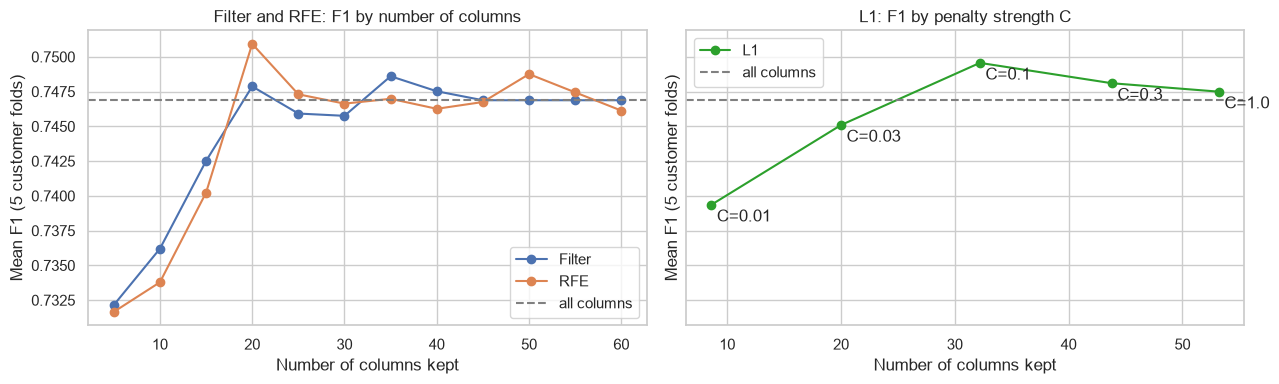

In [20]:
matrices = without_transport            # from now on without transport_method
reference = heldoutf1(matrices)         # all candidate columns


# relevance of every encoded column, both on [0, 1]
def relevance(A, target):
    scores = []
    for col in A.T:
        if np.isin(col, [0, 1]).all():   # one-hot or flag --> Cramér's V
            table = pd.crosstab(col, target)
            scores.append(0 if min(table.shape) < 2 else np.sqrt(chi2_contingency(table, correction=False)[0] / len(col)))
        else:                            # measurement --> |point-biserial r|
            scores.append(abs(pointbiserialr(target, col).statistic))
    return np.nan_to_num(np.array(scores))


# filter order: most relevant first, a column that repeats one already kept (|r| > 0.70) is skipped
def filterorder(A, target):
    corr = np.nan_to_num(np.abs(np.corrcoef(A, rowvar=False)))
    order = []
    for col in np.argsort(-relevance(A, np.asarray(target))):
        if not any(corr[col, kept] > 0.70 for kept in order):
            order.append(col)
    return order


# one ranking per fold: RFE down to 1 column gives the full elimination order, so rank <= k is RFE with k columns
filterorders, rferanks = [], []
for (Atrain, _, _), (trainidx, _) in zip(matrices, splits):
    filterorders.append(filterorder(Atrain, y.iloc[trainidx]))
    rferanks.append(RFE(LogisticRegression(max_iter=2000), n_features_to_select=1).fit(Atrain, y.iloc[trainidx]).ranking_)


def filtermasks(k):
    masks = []
    for (Atrain, _, _), order in zip(matrices, filterorders):
        mask = np.zeros(Atrain.shape[1], bool)
        mask[order[:k]] = True
        masks.append(mask)
    return masks


def rfemasks(k):
    return [ranks <= k for ranks in rferanks]


def l1masks(C):
    return [SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=C, max_iter=5000,
                                               random_state=RANDOMSTATE), threshold=1e-8)
            .fit(Atrain, y.iloc[trainidx]).get_support()
            for (Atrain, _, _), (trainidx, _) in zip(matrices, splits)]


ks = list(range(5, 61, 5))
Cs = [0.01, 0.03, 0.1, 0.3, 1]
curve = pd.DataFrame({"k": ks,
                      "Filter": [heldoutf1(matrices, filtermasks(k)).mean() for k in ks],
                      "RFE": [heldoutf1(matrices, rfemasks(k)).mean() for k in ks]})
l1curve = pd.DataFrame({"C": Cs, "Columns": [np.mean([m.sum() for m in l1masks(C)]) for C in Cs],
                        "L1": [heldoutf1(matrices, l1masks(C)).mean() for C in Cs]})

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for method in ["Filter", "RFE"]:
    axes[0].plot(curve["k"], curve[method], marker="o", label=method)
axes[1].plot(l1curve["Columns"], l1curve["L1"], marker="o", color="tab:green", label="L1")
for C, n, f in l1curve.itertuples(index=False):
    axes[1].annotate(f"C={C}", (n, f), textcoords="offset points", xytext=(4, -12))
for ax in axes:
    ax.axhline(reference.mean(), color="grey", linestyle="--", label="all columns")
    ax.set(xlabel="Number of columns kept", ylabel="Mean F1 (5 customer folds)")
    ax.legend()
axes[0].set_title("Filter and RFE: F1 by number of columns")
axes[1].set_title("L1: F1 by penalty strength C")
plt.tight_layout()
plt.show()

In [21]:
# best width per method (on a tie the smaller one)
k_filter = int(curve.loc[curve["Filter"].idxmax(), "k"])
k_rfe = int(curve.loc[curve["RFE"].idxmax(), "k"])
C_l1 = float(l1curve.loc[l1curve["L1"].idxmax(), "C"])

# check that L1 really sets coefficients to 0 (l1_ratio=1 is the L1 penalty since scikit-learn 1.8, Week 4 and 6)
l1check = LogisticRegression(l1_ratio=1, solver="liblinear", C=C_l1, max_iter=5000).fit(matrices[0][0], y.iloc[splits[0][0]])
print(f"Filter k = {k_filter}, RFE k = {k_rfe}, L1 C = {C_l1}")
print(f"L1 check fold 1: {(l1check.coef_[0] == 0).sum()} of {l1check.coef_.shape[1]} coefficients are exactly 0")

Filter k = 35, RFE k = 20, L1 C = 0.1
L1 check fold 1: 32 of 63 coefficients are exactly 0


In [22]:
# the three selections and the 2 of 3 vote, fold by fold
selected = {"Filter": filtermasks(k_filter), "RFE": rfemasks(k_rfe), "L1": l1masks(C_l1)}
selected["Vote 2 of 3"] = [(f.astype(int) + r + l) >= 2 for f, r, l in zip(*selected.values())]

comparison = {"All columns": {"Columns": np.mean([A.shape[1] for A, _, _ in matrices]), "Mean F1": reference.mean()}}
for method, masks in selected.items():
    scores = heldoutf1(matrices, masks)
    comparison[method] = {"Columns": np.mean([m.sum() for m in masks]), "Mean F1": scores.mean(), **paired(scores, reference)}
pd.DataFrame(comparison).T.round(4).fillna("")

,Columns,Mean F1,dF1,SEM,better in,verdict
All columns,62.6,0.74689,,,,
Filter,35.0,0.748603,0.0017,0.0024,4/5,inside the noise
RFE,20.0,0.750932,0.004,0.0022,4/5,inside the noise
L1,32.2,0.749564,0.0027,0.0025,2/5,inside the noise
Vote 2 of 3,26.4,0.749655,0.0028,0.0016,4/5,inside the noise


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>Below about 15 columns every method <b>loses</b> F1, from about 20 columns on the curves are flat --> most of the 63 columns are not needed</li>
  <li>The best widths are <b>k = 35</b> for the filter, <b>k = 20</b> for RFE and <b>C = 0.1</b> for L1 (32 columns). L1 really sets 32 of 63 coefficients to exactly 0</li>
  <li>No selection is <b>better or worse</b> than all columns on the customer folds: every difference is <b>inside the noise</b> (smaller than 2 SEM), e.g. the vote +0.0028 ± 0.0015</li>
  <li>We use the <b>2 of 3 vote</b> (as in Week 4): a column stays only if two different families agree, so the set depends less on one method.
  It keeps <b>26 of 63 columns</b> at the same F1. In 4.3 we check if the smaller set also helps on later data</li>
</ul>

</div>

<a id="model"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>4. Model and assessment</h2>
<h3>4.1 Metric</h3>
<ul>
  <li>We use the <b>F1 of class 1</b> (repeat purchase): it combines precision and recall, so a model can not win by calling everybody a repeat buyer or by being too careful</li>
  <li>Classes are only a bit imbalanced (56% repeat), so <b>always predicting 1</b> already gives a high F1 --> this is the floor every model has to beat</li>
  <li>We also show precision, recall and AUC (ranking quality, independent of the threshold)</li>
</ul>
<h3>4.2 Model families</h3>
<p>Models from Weeks 5 and 6 on the customer folds: a dummy baseline, the logistic regression and the decision tree (max_depth and min_samples_leaf).
The vote from Section 3 is part of the model, so it is refitted in every training fold.</p>

</div>

In [23]:
# the vote of Section 3 on the training rows of one fold, returns the mask
def votemask(A, target):
    f = np.isin(np.arange(A.shape[1]), filterorder(A, target)[:k_filter])
    r = RFE(LogisticRegression(max_iter=2000), n_features_to_select=k_rfe).fit(A, target).support_
    l = SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=C_l1, max_iter=5000,
                                           random_state=RANDOMSTATE), threshold=1e-8).fit(A, target).get_support()
    return (f.astype(int) + r + l) >= 2


candidates = {"Always 1 (dummy)": DummyClassifier(strategy="constant", constant=1),
              "LogReg": LogisticRegression(max_iter=2000),
              "LogReg, class_weight=balanced": LogisticRegression(class_weight="balanced", max_iter=2000)}
candidates.update({f"Tree depth={d}, leaf={leaf}": DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=RANDOMSTATE)
                   for d in [3, 5, 8] for leaf in [25, 100]})

masks = [votemask(Atrain, y.iloc[tr]) for (Atrain, _, _), (tr, _) in zip(matrices, splits)]
rows = {}
for name, model in candidates.items():
    res = []
    for (Atrain, Aval, _), (tr, va), m in zip(matrices, splits, masks):
        fitted = clone(model).fit(Atrain[:, m], y.iloc[tr])
        prob = fitted.predict_proba(Aval[:, m])[:, 1]
        pred = (prob >= 0.5).astype(int)
        res.append([f1_score(y.iloc[tr], fitted.predict(Atrain[:, m])), f1_score(y.iloc[va], pred),
                    precision_score(y.iloc[va], pred), recall_score(y.iloc[va], pred), roc_auc_score(y.iloc[va], prob)])
    rows[name] = np.mean(res, axis=0)
pd.DataFrame(rows, index=["Train F1", "Validation F1", "Precision", "Recall", "AUC"]).T.round(4).sort_values("AUC", ascending=False)

,Train F1,Validation F1,Precision,Recall,AUC
LogReg,0.7536,0.7497,0.7575,0.7422,0.7883
"LogReg, class_weight=balanced",0.7385,0.7319,0.7879,0.6835,0.7883
"Tree depth=5, leaf=100",0.7337,0.7186,0.7621,0.6806,0.7686
"Tree depth=8, leaf=100",0.7406,0.7216,0.7517,0.6957,0.7682
"Tree depth=5, leaf=25",0.7373,0.7221,0.7612,0.6890,0.7640
"Tree depth=3, leaf=100",0.7230,0.7197,0.7479,0.7023,0.7618
"Tree depth=3, leaf=25",0.7230,0.7197,0.7479,0.7023,0.7615
"Tree depth=8, leaf=25",0.7637,0.7243,0.7413,0.7086,0.7575
Always 1 (dummy),0.7177,0.7175,0.5597,1.0000,0.5000


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The logistic regression beats the <b>always-1 floor</b> (F1 0.7175) and all trees. The trees have a lower AUC (0.76 to 0.77 vs 0.79) and with depth 8 a bigger gap between train and validation --> they overfit more</li>
  <li><b>class_weight="balanced"</b> gives class 0 more weight, so the model predicts fewer 1s: higher precision, much lower recall and a lower F1 --> not used</li>
  <li>--> we continue with the <b>logistic regression</b></li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.3 Tuning for later purchases</h3>
<p>test.csv holds <b>later purchases</b> (May 2025 to Oct 2026), and 95% of them come from customers that are already in train.csv.
The customer folds ask a different question (new customers). A <b>time split</b> asks the same question as test.csv (Week 5, 3.4):
train on the past and validate on the next period. On these folds we tune the logistic regression:</p>
<ul>
  <li><b>C</b>, the inverse strength of the L2 penalty (Week 6)</li>
  <li><b>all columns or the vote</b> from Section 3</li>
  <li><b>clientes</b>: Task 2 left country_or_region and island_known out, because they added almost nothing on the customer folds. For known customers they could matter more, so we test them again</li>
</ul>
<p>We choose by the mean F1 at the default threshold 0.5 and show the AUC next to it.</p>

</div>

In [24]:
order = pd.to_datetime(X["purchase_date"]).sort_values(kind="stable").index
Xtime, ytime = X.loc[order].reset_index(drop=True), y.loc[order].reset_index(drop=True)
timesplits = list(TimeSeriesSplit(n_splits=5).split(Xtime))

FEATURESETS = {"Task 2 features": (FLAGS, CATEGORICAL_NOID),
               "+ clientes": (FLAGS + ["island_known"], CATEGORICAL_NOID + ["country_or_region"])}
grid, timeprobs = {}, {}
for setname, (flags, categorical) in FEATURESETS.items():
    timematrices = foldmatrices(categorical, folds=timesplits, frame=Xtime, flags=flags)
    timevotes = [votemask(A, ytime.iloc[tr]) for (A, _, _), (tr, _) in zip(timematrices, timesplits)]
    for columns, colmasks in {"all columns": None, "vote": timevotes}.items():
        for C in [0.01, 0.03, 0.1, 0.3, 1]:
            probs = heldoutprob(timematrices, colmasks, LogisticRegression(C=C, max_iter=5000), timesplits, ytime)
            timeprobs[(setname, columns, C)] = probs
            grid[(setname, columns, C)] = {"AUC": foldscores(probs, timesplits, ytime, metric="AUC").mean(),
                                           "F1 at 0.5": foldscores(probs, timesplits, ytime).mean()}

grid = pd.DataFrame(grid).T.rename_axis(["Features", "Columns", "C"])
BEST = grid["F1 at 0.5"].idxmax()
display(grid.round(4).unstack("C"))

f1at = lambda key: foldscores(timeprobs[key], timesplits, ytime)
print("chosen:", BEST)
print("vs. the setup from the customer folds (Task 2 features, vote, C=1):", paired(f1at(BEST), f1at(("Task 2 features", "vote", 1))))
print("vs. the same model with the default C=1:                            ", paired(f1at(BEST), f1at(BEST[:2] + (1,))))
print("vs. the same model without clientes:                                ", paired(f1at(BEST), f1at(("Task 2 features",) + BEST[1:])))

AUC                                 F1 at 0.5  \
C                              0.01    0.03    0.10    0.30    1.00      0.01   
Features        Columns                                                         
+ clientes      all columns  0.7950  0.7960  0.7946  0.7915  0.7861    0.7615   
                vote         0.7926  0.7925  0.7905  0.7872  0.7815    0.7537   
Task 2 features all columns  0.7942  0.7950  0.7929  0.7888  0.7824    0.7603   
                vote         0.7937  0.7938  0.7918  0.7885  0.7829    0.7565   

                                                             
C                              0.03    0.10    0.30    1.00  
Features        Columns                                      
+ clientes      all columns  0.7618  0.7564  0.7485  0.7419  
                vote         0.7527  0.7500  0.7465  0.7442  
Task 2 features all columns  0.7598  0.7559  0.7475  0.7376  
                vote         0.7554  0.7540  0.7513  0.7482

chosen: ('+ clientes', 'all columns', np.float64(0.03))
vs. the setup from the customer folds (Task 2 features, vote, C=1): {'dF1': 0.0136, 'SEM': 0.0062, 'better in': '4/5', 'verdict': 'better'}
vs. the same model with the default C=1:                             {'dF1': 0.02, 'SEM': 0.004, 'better in': '5/5', 'verdict': 'better'}
vs. the same model without clientes:                                 {'dF1': 0.002, 'SEM': 0.0019, 'better in': '3/5', 'verdict': 'inside the noise'}


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>A <b>stronger penalty</b> clearly helps on later data: from C = 1 to C = 0.03 the AUC goes from 0.786 to 0.796 and F1 from 0.742 to 0.762 (+0.020 ± 0.004, better in 5 of 5 folds). With a weak penalty the model follows old patterns too closely</li>
  <li>With C = 1 the <b>vote</b> is better than all columns, with a strong penalty it is the other way round (0.7618 vs 0.7527). Selection and the L2 penalty do the same job (Week 4 and 6): the penalty shrinks weak columns instead of dropping them, so the small signal they still carry is kept</li>
  <li><b>clientes</b> adds only a little (+0.002, inside the noise), but it has the highest mean, so we take it</li>
  <li>Final choice: <b>all columns + clientes, C = 0.03</b>. Compared with the setup from the customer folds this is <b>better</b> (+0.0136 ± 0.0062)</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.4 Threshold</h3><p>The model gives a probability and 0.5 is only the default cut-off (Week 5). We look at F1 on the time folds for every threshold of the chosen model.</p>

</div>

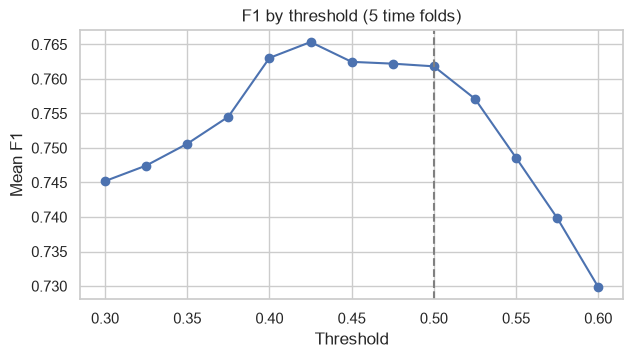

best threshold 0.425 vs 0.5: {'dF1': 0.0035, 'SEM': 0.0037, 'better in': '3/5', 'verdict': 'inside the noise'} --> we use 0.5


,Validation period,F1 setup from customer folds,F1 final model
0,Aug 2017 to Jan 2019,0.7607,0.7733
1,Jan 2019 to Oct 2020,0.7318,0.7481
2,Oct 2020 to Mar 2022,0.7540,0.7682
3,Mar 2022 to Sep 2023,0.7009,0.7329
4,Sep 2023 to Feb 2025,0.7938,0.7867


In [25]:
thresholds = np.round(np.arange(0.3, 0.61, 0.025), 3)
thresholdcurve = pd.DataFrame({t: foldscores(timeprobs[BEST], timesplits, ytime, threshold=t) for t in thresholds}).T
besthreshold = float(thresholdcurve.mean(axis=1).idxmax())
check = paired(thresholdcurve.loc[besthreshold], thresholdcurve.loc[0.5])
THRESHOLD = besthreshold if check["verdict"] == "better" else 0.5   # only move away from the default if it clearly helps

ax = thresholdcurve.mean(axis=1).plot(marker="o", figsize=(7, 3.5))
ax.axvline(THRESHOLD, color="grey", linestyle="--")
ax.set(title="F1 by threshold (5 time folds)", xlabel="Threshold", ylabel="Mean F1")
plt.show()
print(f"best threshold {besthreshold} vs 0.5:", check, f"--> we use {THRESHOLD}")

# final check: the chosen model fold by fold
periods = [f"{pd.to_datetime(Xtime['purchase_date'].iloc[va[0]]):%b %Y} to {pd.to_datetime(Xtime['purchase_date'].iloc[va[-1]]):%b %Y}"
           for _, va in timesplits]
pd.DataFrame({"Validation period": periods,
              "F1 setup from customer folds": f1at(("Task 2 features", "vote", 1)),
              "F1 final model": foldscores(timeprobs[BEST], timesplits, ytime, threshold=THRESHOLD)}).round(4)

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The curve is <b>flat between 0.40 and 0.50</b>. The best value (0.425) is only +0.0035 ± 0.0037 better than 0.5 --> inside the noise, so we keep the <b>default 0.5</b>. With the strong penalty the probabilities are pulled to the middle, so the default already fits</li>
  <li>The final model is better in 4 of 5 periods. Only in the newest period the old setup is a bit higher (0.794 vs 0.787) --> on Kaggle we expect around 0.79</li>
</ul>

</div>

<a id="finalset"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>5. Final model and feature set</h2><p>We refit the chosen pre-processing and model on every training row and read the coefficients per original variable. All inputs are scaled, so the size of a coefficient shows how much the model uses it.</p>

</div>

In [26]:
finalflags, finalcategorical = FEATURESETS[BEST[0]]
finalprep = preprocessor(NUMERIC, finalflags, finalcategorical)
Aall = finalprep.fit_transform(X)
allnames = finalprep.named_steps["columns"].get_feature_names_out()
finalmodel = LogisticRegression(C=BEST[2], max_iter=5000).fit(Aall, y)


# encoded column --> original variable
def source(name):
    name = name.split("__", 1)[1]
    return next((c for c in finalcategorical if name.startswith(c + "_")), name)


# how often the vote of Section 3 kept a variable in the 5 customer folds (for a variable with dummies: its best dummy)
votefolds = pd.Series([sum(name in names[m] for (_, _, names), m in zip(matrices, selected["Vote 2 of 3"]))
                       for name in allnames], index=allnames)
finaltable = (pd.DataFrame({"Variable": [source(n) for n in allnames], "Weight": np.abs(finalmodel.coef_[0]),
                            "Vote folds": votefolds.values})
              .groupby("Variable").agg(Columns=("Weight", "size"), Weight=("Weight", "sum"), Vote=("Vote folds", "max"))
              .sort_values("Weight", ascending=False))
finaltable["Share of weight"] = (finaltable["Weight"] / finaltable["Weight"].sum()).map("{:.0%}".format)
finaltable.loc[["country_or_region", "island_known"], "Vote"] = np.nan   # clientes was not part of Section 3
print(f"{len(allnames)} encoded columns from {len(finaltable)} original variables, C = {BEST[2]}, threshold = {THRESHOLD}")
display(finaltable.round(3))

68 encoded columns from 39 original variables, C = 0.03, threshold = 0.5


,Columns,Weight,Vote,Share of weight
Variable,,,,
month,12,2.326,5.0,27%
salesperson,8,0.900,5.0,10%
purchase_count_365d,1,0.627,5.0,7%
payment_type,7,0.553,5.0,6%
purchase_count_90d,1,0.410,5.0,5%
island_known,1,0.335,NaN,4%
customer_tenure_days,1,0.241,1.0,3%
country_or_region,3,0.221,NaN,3%
prior_purchase_count,1,0.208,1.0,2%


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Final feature set and rationale</b></p>
<ul>
  <li>Final feature set: <b>all candidate variables from Task 2 without transport_method (Section 2), plus country_or_region and island_known from clientes</b> --> 39 variables, 68 encoded columns. We do not drop columns, the L2 penalty (C = 0.03) shrinks the weak ones (4.3)</li>
  <li><b>Most weight</b> (for a variable with dummies it is the sum over its dummies): month (27%), salesperson (10%), purchase_count_365d (7%), payment_type (6%) and purchase_count_90d (5%) --> how often someone buys plus the patterns from Task 1 (8.3) and Task 2 (3.1), e.g. Payment 9 repeats 95%, Master 4 only 39%, March is the weakest month</li>
  <li>These top variables were also kept by the vote in <b>all 5 folds</b> (Section 3), and 9 of the 11 variables the vote never kept get at most 1% of the weight (e.g. Total Liquido, Custo, spend_90d, purchases_per_year) --> both ways agree on what matters</li>
  <li>clientes (island_known 4%, country_or_region 3%) adds region information about the customer that the purchase columns do not have</li>
</ul>

</div>

<a id="submission"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>6. Predictions for test.csv</h2><p>test.csv gets the same clientes join and is only transformed with the pre-processing fitted on train. Nothing is fitted on it.</p>

</div>

In [27]:
test = addclientes(pd.read_csv(DATA_DIR / "test.csv"))
prediction = (finalmodel.predict_proba(finalprep.transform(test))[:, 1] >= THRESHOLD).astype(int)

submission = pd.DataFrame({"ID": test["ID"], TARGET: prediction})
assert len(submission) == len(test) and submission["ID"].is_unique
submission.to_csv("Homework_Group30_submission.csv", index=False)
print(f"{len(submission)} predictions saved, share of 1: {prediction.mean():.2f}")
submission.head()

986 predictions saved, share of 1: 0.66


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Kaggle</b>: besides our own validation we also tested many changes directly on the public leaderboard (28 submissions) and used the score as an extra check. This file scored <b>0.793</b>; the first version (C = 1, vote, threshold 0.4) had 0.789 and the same model with threshold 0.425 had 0.788. Because we chose partly by this score, 0.793 is a bit optimistic. Our own estimate is the time-split F1 of 0.762 (4.3).</p>

</div>